# Commodities dataset analysis

This notebook loads the Washington commodities dataset, tests the dataframe, filters and groups records by commodity, classifies commodity labels, and predicts price-received values. The outputs are exploratory and should not be treated as market or farm-management advice.

## Variable glossary

| Variable | Meaning |
|---|---|
| `Program` | USDA survey or census program source. |
| `Year` | Reporting year. |
| `Period` | Reporting period, such as a month, year, or survey week. |
| `Geo Level` | Geographic aggregation level, such as state. |
| `State` | State associated with the observation. |
| `County` | County when the record is reported below the state level. |
| `Commodity` | Commodity or agricultural category being measured. |
| `Data Item` | Specific measure, such as price received or production. |
| `Domain` / `Domain Category` | Survey grouping and subgroup labels. |
| `Value` | Numeric observation. Its unit is described in `Data Item`. |
| `CV (%)` | Coefficient of variation, when supplied. |

The model uses `Commodity` as the classification target. Price prediction is restricted to rows whose `Data Item` contains `PRICE RECEIVED` and predicts the numeric `Value`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from numbers_parser import Document

numbers_path = Path('/Users/warrenbuenarte/Library/CloudStorage/OneDrive-Personal/Commodities.numbers')
if not numbers_path.exists():
    raise FileNotFoundError(f'Dataset not found: {numbers_path}')

document = Document(str(numbers_path))
table = document.sheets[0].tables[0]
rows = [[cell.value for cell in row] for row in table.rows()]
if not rows:
    raise ValueError('The Numbers workbook does not contain any rows')

df = pd.DataFrame(rows[1:], columns=rows[0])
df.head()

,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,...,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
0,SURVEY,2024.0,APR,None,STATE,WASHINGTON,53.0,None,None,None,...,None,None,0.0,None,BARLEY,"BARLEY - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,8.26,None
1,SURVEY,2024.0,APR,None,STATE,WASHINGTON,53.0,None,None,None,...,None,None,0.0,None,BARLEY,"BARLEY - SALES, MEASURED IN PCT OF MKTG YEAR",TOTAL,NOT SPECIFIED,5.0,None
2,SURVEY,2024.0,APR,None,STATE,WASHINGTON,53.0,None,None,None,...,None,None,0.0,None,BARLEY,"BARLEY, FEED - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.75,None
3,SURVEY,2024.0,APR,None,STATE,WASHINGTON,53.0,None,None,None,...,None,None,0.0,None,BARLEY,"BARLEY, MALTING - PRICE RECEIVED, MEASURED IN ...",TOTAL,NOT SPECIFIED,(D),None
4,SURVEY,2024.0,APR,None,STATE,WASHINGTON,53.0,None,None,None,...,None,None,0.0,None,HAY,"HAY - PRICE RECEIVED, MEASURED IN $ / TON",TOTAL,NOT SPECIFIED,205.0,None


In [2]:
# Clean types and verify the dataframe before modeling.
text_columns = ['Commodity', 'Data Item', 'Period', 'State', 'Program', 'Geo Level', 'Domain', 'Domain Category']
for column in text_columns:
    df[column] = df[column].fillna('Unknown').astype(str).str.strip()
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df['Value'] = pd.to_numeric(df['Value'], errors='coerce')
df['CV (%)'] = pd.to_numeric(df['CV (%)'], errors='coerce')
df = df.dropna(subset=['Year', 'Value']).reset_index(drop=True)
print(f'Rows: {len(df):,}')
print(f'Columns: {len(df.columns)}')
print(f'Commodity labels: {df.Commodity.nunique()}')
df[['Commodity', 'Data Item', 'Year', 'Value']].head()

Rows: 5,299
Columns: 21
Commodity labels: 45


,Commodity,Data Item,Year,Value
0,BARLEY,"BARLEY - PRICE RECEIVED, MEASURED IN $ / BU",2024.0,8.26
1,BARLEY,"BARLEY - SALES, MEASURED IN PCT OF MKTG YEAR",2024.0,5.00
2,BARLEY,"BARLEY, FEED - PRICE RECEIVED, MEASURED IN $ / BU",2024.0,3.75
3,HAY,"HAY - PRICE RECEIVED, MEASURED IN $ / TON",2024.0,205.00
4,HAY,"HAY - SALES, MEASURED IN PCT OF MKTG YEAR",2024.0,4.00


## Filter and group by commodity

The first summary counts records and calculates average observed values. The price summary isolates price-received records so production, acreage, and percentage measures are not mixed with dollars per unit.

In [3]:
commodity_summary = (
    df.groupby('Commodity', as_index=False)
    .agg(records=('Commodity', 'size'), mean_value=('Value', 'mean'), median_value=('Value', 'median'))
    .sort_values('records', ascending=False)
)
price_df = df[df['Data Item'].str.contains('PRICE RECEIVED', case=False, na=False)].copy()
price_summary = (
    price_df.groupby('Commodity', as_index=False)
    .agg(price_records=('Commodity', 'size'), mean_price=('Value', 'mean'), median_price=('Value', 'median'))
    .sort_values('price_records', ascending=False)
)
print('Top commodity groups')
display(commodity_summary.head(12).round(2))
print(f'Price-received records: {len(price_df):,}')
display(price_summary.head(12).round(2))

Top commodity groups


,Commodity,records,mean_value,median_value
44,WHEAT,1011,3162501.53,20.0
39,SOIL,560,25.00,24.0
32,PASTURELAND,525,20.00,18.0
11,CORN,424,638174.72,23.0
2,BARLEY,399,192161.73,24.0
35,POTATOES,361,7711867.94,16.0
3,BEANS,330,200802.84,28.0
31,ONIONS,301,1827004.63,13.0
34,PEAS,278,189003.92,15.0
5,"BEDDING PLANTS, ANNUAL",202,857765.55,4500.0


Price-received records: 222


,Commodity,price_records,mean_price,median_price
4,"BEDDING PLANTS, ANNUAL",53,12.09,11.38
28,WHEAT,39,5.42,5.31
15,HAY,39,203.26,205.00
2,BARLEY,11,5.49,5.27
9,CHICKPEAS,7,32.27,32.80
12,"FLOWERING PLANTS, POTTED",7,9.58,10.35
7,CANOLA,7,18.47,17.90
11,CUT FLOWERS,6,2.32,0.94
14,GRAPES,6,940.67,940.00
5,"BEDDING PLANTS, HERBACEOUS PERENNIAL",6,5.53,5.48


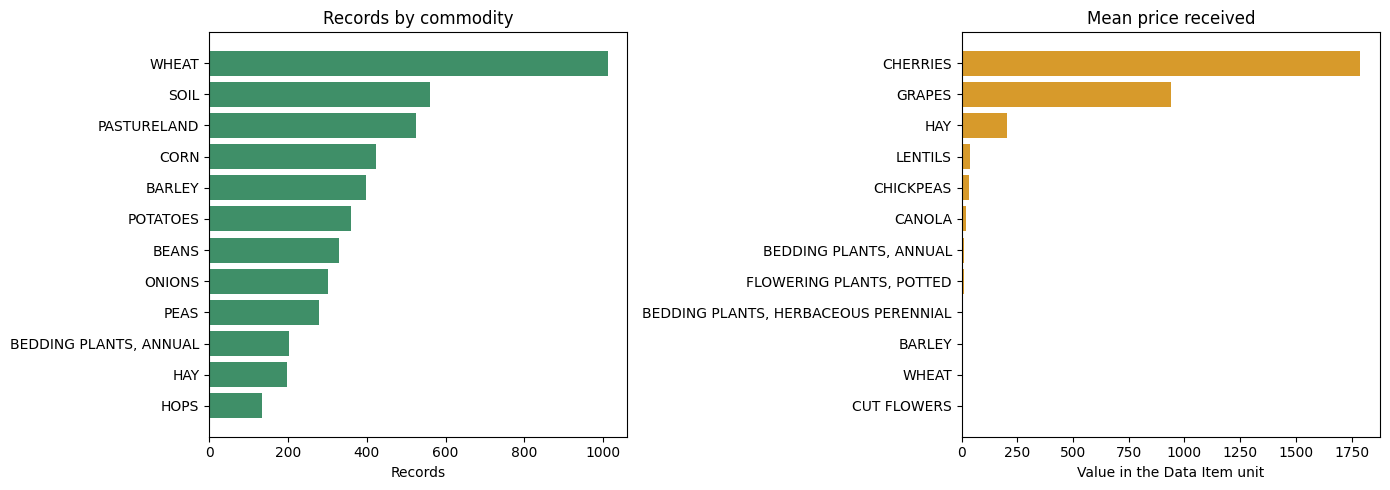

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top = commodity_summary.head(12).sort_values('records')
axes[0].barh(top['Commodity'], top['records'], color='#3f8f68')
axes[0].set_title('Records by commodity')
axes[0].set_xlabel('Records')
top_prices = price_summary.head(12).sort_values('mean_price')
axes[1].barh(top_prices['Commodity'], top_prices['mean_price'], color='#d79a2b')
axes[1].set_title('Mean price received')
axes[1].set_xlabel('Value in the Data Item unit')
plt.tight_layout()
plt.show()

## Commodity classification

**Selected algorithm: TF-IDF + Logistic Regression.** The text model learns which words and phrases in `Data Item` are associated with each commodity label. This is appropriate for a categorical classification test because the data item descriptions contain structured commodity language. Classes with fewer than eight records are excluded from the holdout experiment so every retained class can contribute to training and testing.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

class_counts = df['Commodity'].value_counts()
classification_df = df[df['Commodity'].isin(class_counts[class_counts >= 8].index)].copy()
classification_text = classification_df['Data Item'] + ' ' + classification_df['Domain'] + ' ' + classification_df['Period']
X_train, X_test, y_train, classification_y_test = train_test_split(
    classification_text, classification_df['Commodity'], test_size=0.25, random_state=42, stratify=classification_df['Commodity']
)
classifier = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
classifier.fit(X_train, y_train)
classification_predictions = classifier.predict(X_test)
# Keep this holdout separate from the price regression target below.
classification_metrics = {
    'accuracy': float(accuracy_score(classification_y_test, classification_predictions)),
    'classes': int(classification_df['Commodity'].nunique()),
    'train_records': int(len(X_train)),
    'test_records': int(len(X_test)),
}
print(classification_metrics)
print(classification_report(classification_y_test, classification_predictions, zero_division=0))

{'accuracy': 0.9878603945371776, 'classes': 36, 'train_records': 3953, 'test_records': 1318}
                                      precision    recall  f1-score   support

                              APPLES       1.00      1.00      1.00         3
                            APRICOTS       1.00      1.00      1.00         2
                              BARLEY       1.00      0.97      0.98       100
                               BEANS       1.00      1.00      1.00        83
              BEDDING PLANTS, ANNUAL       1.00      1.00      1.00        51
BEDDING PLANTS, HERBACEOUS PERENNIAL       1.00      1.00      1.00         7
                         BLUEBERRIES       1.00      1.00      1.00         3
                              CANOLA       1.00      1.00      1.00         6
                            CHERRIES       1.00      1.00      1.00         3
                           CHICKPEAS       0.91      1.00      0.95        10
                                CORN       1.00 

In [6]:
# Show where the classifier performs best and where it confuses labels.
report = pd.DataFrame(classification_report(classification_y_test, classification_predictions, output_dict=True, zero_division=0)).T
classification_by_class = report.loc[report.index.isin(classifier.classes_), ['precision', 'recall', 'f1-score', 'support']].sort_values('f1-score', ascending=False)
classification_by_class.head(10).round(3)

,precision,recall,f1-score,support
APPLES,1.0,1.0,1.0,3.0
PEAS,1.0,1.0,1.0,70.0
PASTURELAND,1.0,1.0,1.0,131.0
ONIONS,1.0,1.0,1.0,75.0
MINT,1.0,1.0,1.0,4.0
SOIL,1.0,1.0,1.0,140.0
SUGARBEETS,1.0,1.0,1.0,6.0
HEMP,1.0,1.0,1.0,5.0
HAYLAGE,1.0,1.0,1.0,2.0
HAY & HAYLAGE,1.0,1.0,1.0,3.0


## Price predictive modeling

**Selected algorithm: Random Forest Regressor.** The model predicts the numeric price-received `Value` from commodity, reporting year, period, state, and survey metadata. A random forest captures nonlinear relationships and interactions without assuming a straight-line price trend. This is a baseline forecast, not a financial forecast.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder

price_model_df = price_df[price_df['Value'] >= 0].copy()
price_model_df['PeriodCode'] = price_model_df['Period'].str.extract(r'(\d+)')[0].fillna('0').astype(float)
price_features = ['Year', 'PeriodCode', 'Commodity', 'State', 'Domain', 'Domain Category']
X = price_model_df[price_features]
y = price_model_df['Value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
price_preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), ['Commodity', 'State', 'Domain', 'Domain Category']),
    ('numeric', 'passthrough', ['Year', 'PeriodCode']),
])
price_model = Pipeline([
    ('preprocessor', price_preprocessor),
    ('model', RandomForestRegressor(n_estimators=200, random_state=42, min_samples_leaf=2)),
])
price_model.fit(X_train, y_train)
price_predictions = price_model.predict(X_test)
price_metrics = {
    'mae': float(mean_absolute_error(y_test, price_predictions)),
    'rmse': float(mean_squared_error(y_test, price_predictions) ** 0.5),
    'r2': float(r2_score(y_test, price_predictions)),
    'train_records': int(len(X_train)),
    'test_records': int(len(X_test)),
}
print(price_metrics)

{'mae': 130.59978270663547, 'rmse': 294.34629939157224, 'r2': 0.5124876930638675, 'train_records': 166, 'test_records': 56}


In [8]:
# Compare actual and predicted values for a small test sample.
prediction_sample = pd.DataFrame({'actual': y_test.to_numpy(), 'predicted': price_predictions}).head(12).round(2)
prediction_sample

,actual,predicted
0,3.18,13.25
1,12.06,8.94
2,5.06,5.44
3,8.22,13.25
4,2.44,13.25
5,31.70,65.91
6,10.40,231.20
7,5.49,5.44
8,0.26,249.47
9,0.99,378.73


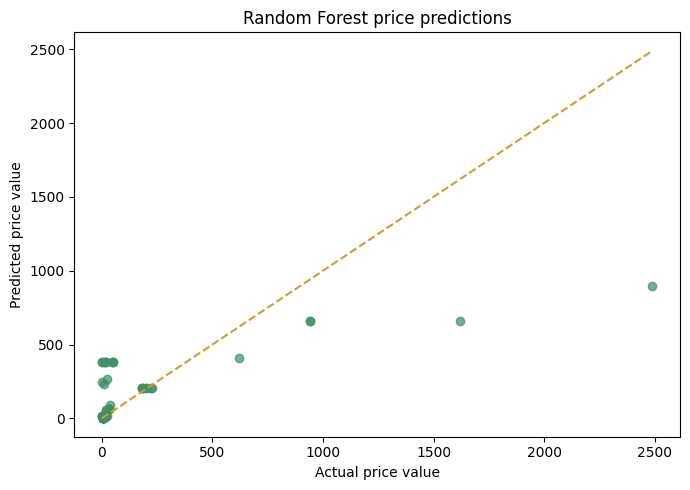

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, price_predictions, alpha=0.7, color='#3f8f68')
line_min, line_max = float(min(y_test.min(), price_predictions.min())), float(max(y_test.max(), price_predictions.max()))
ax.plot([line_min, line_max], [line_min, line_max], '--', color='#d79a2b')
ax.set_title('Random Forest price predictions')
ax.set_xlabel('Actual price value')
ax.set_ylabel('Predicted price value')
plt.tight_layout()
plt.show()

## Conclusions and limitations

- Commodity grouping shows which categories contribute the most records and which have price observations.
- The TF-IDF classifier tests whether structured data-item language can identify commodity labels; it is not a vision or agronomic classifier.
- The Random Forest regressor provides a baseline for price prediction, but market forecasts require more years, external market variables, and time-based validation.
- `Value` units vary by `Data Item`, so mean values should only be compared within the same measure.
- The app will display these results as exploratory analytics, not recommendations or guaranteed predictions.

In [10]:
import json

# Compact export consumed by the web app.
app_data = {
    'metadata': {
        'title': 'Washington commodities analytics',
        'source': 'Commodities export from Apple Numbers',
        'record_count': int(len(df)),
        'commodity_count': int(df['Commodity'].nunique()),
        'year_start': int(df['Year'].min()),
        'year_end': int(df['Year'].max()),
        'model_note': 'Classification and price prediction are exploratory baselines; Value units vary by Data Item.',
    },
    'commodity_summary': [
        {'commodity': str(row['Commodity']), 'records': int(row['records']), 'mean_value': round(float(row['mean_value']), 2), 'median_value': round(float(row['median_value']), 2)}
        for _, row in commodity_summary.iterrows()
    ],
    'price_summary': [
        {'commodity': str(row['Commodity']), 'price_records': int(row['price_records']), 'mean_price': round(float(row['mean_price']), 2), 'median_price': round(float(row['median_price']), 2)}
        for _, row in price_summary.iterrows()
    ],
    'classification': classification_metrics,
    'classification_top_classes': [
        {'commodity': str(index), 'precision': round(float(row['precision']), 3), 'recall': round(float(row['recall']), 3), 'f1': round(float(row['f1-score']), 3), 'support': int(row['support'])}
        for index, row in classification_by_class.head(8).iterrows()
    ],
    'price_model': price_metrics,
    'classification_confusion_matrix': confusion_matrix(classification_y_test, classification_predictions, labels=classifier.classes_).tolist(),
    'classification_labels': [str(label) for label in classifier.classes_],
}
Path('data/commodities-analytics.json').write_text(json.dumps(app_data, separators=(',', ':')) + '\n')
print('Wrote data/commodities-analytics.json')

Wrote data/commodities-analytics.json
